# Motivation and intention

A very simple scanning algorithm for identifying (or guessing) the local update rule.

# Loading packages and functions

In [1]:
# Helper libraries
import numpy as np
import matplotlib.pyplot as plt
import json

# fix random seed for reproducibility
seed = 2023
np.random.seed(seed)

# change matplotlib plot to Times New Roman (for Springer book)

In [2]:
# uncomment if you want to use Drive

from google.colab import drive
drive.mount('/content/gdrive')

images_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Images'
models_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Models'
files_dir = '/content/gdrive/My Drive/Colab Notebooks/Cellular Automata/Spacetime Diagram Classification/Files'
# !ls '/content/gdrive/My Drive/'

Mounted at /content/gdrive


## User-defined functions

In [3]:
# Load function to translate rule to Li-Packard classes (for loading/showing data)
# Note: This function is very poorly designed (slow)

def whichClass(dictionary, rules, class_to_num=None):
    keys = []
    for i, rule in enumerate(rules):
      for key, array in dictionary.items():
          if np.isin(rule, array):
            if class_to_num: # digits rather than strings
              keys.append(class_to_num[key])
            else: # strings rather than digits
              keys.append(key)
    return np.array(keys)

# Translate rule to Li-Packard class
with open(f"{files_dir}/all_Li-Packard_dict.json", "r") as fp:
    # Load the dictionary from the file
    Li_Packard_dict = json.load(fp)

def _base_repr(number, base=2, length=8):
    base_repr = np.base_repr(number, base=base)
    if len(base_repr) < length:
        extra_zeros = (length - len(base_repr)) * '0'
        base_repr = extra_zeros + base_repr
    return base_repr

In [4]:
# Define function to scan a diagram for all triplets

def scan_diagram_for_triplets(diagram):
  timesteps, cells, _ = diagram.shape
  periodic_diagram = _return_periodic_diagram(diagram)
  remaining_triplets = set({'000', '001', '010', '011', '100', '101', '110', '111'})
  found_triplets = set({})
  # Scan all but the last timestep, until all triplets are found
  for timestep in range(timesteps-1):
    # only search for triplets that we haven't seen yet
    remaining_triplets = remaining_triplets.difference(found_triplets)
    # turn current timestep in a long string
    current_config = periodic_diagram[timestep,:,0]
    current_config_as_str = np.array2string(current_config, separator='')[1:-1]
    # search for all remaining triplets in this timestep string
    for triplet in remaining_triplets:
      if triplet in current_config_as_str:
        found_triplets.add(triplet)
        # abort once we found all triplets
        if len(found_triplets) == 8:
          return found_triplets
  # in case no early abort happens, simply return all triplets that _have_ been found
  return found_triplets

# define function to make diagram with periodic boundary conditions
def _return_periodic_diagram(diagram):
  # input shape (T,N,1)
  first_col = np.expand_dims(diagram[:,0],axis=1)
  last_col = np.expand_dims(diagram[:,-1],axis=1)
  periodic_diagram = np.copy(diagram)
  periodic_diagram = np.concatenate((first_col, periodic_diagram, last_col),axis=1)
  return periodic_diagram

# Loading data

In [5]:
# all 1024 x 256 training set diagrams
train_name_prefix = "ECAs_1024sims-per-rule_64x64"
train_diagram_name = train_name_prefix + "_train_diagrams.npy"
train_label_name = train_name_prefix + "_train_labels.npy"

# all 128 x 256 test set diagrams
test_name_prefix = "ECAs_128sims-per-rule_64x64"
test_diagram_name = test_name_prefix + "_test_diagrams.npy"
test_label_name = test_name_prefix + "_test_labels.npy"

# takes a couple of seconds to actually load them
x_train_all = np.load(f"{files_dir}/{train_diagram_name}")
r_train_rule_all = np.load(f"{files_dir}/{train_label_name}")
x_test_all = np.load(f"{files_dir}/{test_diagram_name}")
r_test_rule_all = np.load(f"{files_dir}/{test_label_name}")

## Scan through all data and save ID of incomplete diagrams

In [6]:
# takes about a minute for 200k 64x64 diagrams
verbose=True

training_set_size = x_train_all.shape[0]
test_set_size = x_test_all.shape[0]

print(f"Working on training set ({training_set_size} samples)")
# create empty dictionary: indices as keys, (rule, triplets) as items
undetermined_train = dict({})
# create a list to append the rules to, used in the histogram
undetermined_train_rules = []
# keep the user up to speed on how many diagrams have been inspected
print_every = 25000
for i, (rule, diagram) in enumerate(zip(r_train_rule_all, x_train_all)):
  if i % print_every == 0:
    processed = (i // print_every) * print_every
    print(f"Processed {processed} samples.")
  found_triplets = scan_diagram_for_triplets(diagram)
  len_found_triplets = len(found_triplets)
  if len_found_triplets < 8:
    if verbose:
      print(f'found one at index {i}')
    undetermined_train[i] = (rule[0], found_triplets)
    undetermined_train_rules.append(rule[0])
print(f"Processed all samples. Found {len(undetermined_train_rules)} undetermined diagrams.")

# same but for test set
print("")
print(f"Working on test set ({test_set_size} samples)")
undetermined_test = dict({})
undetermined_test_rules = [] # list for histogram
print_every = 10000
for i, (rule, diagram) in enumerate(zip(r_test_rule_all, x_test_all)):
  if i % print_every == 0:
    processed = (i // print_every) * print_every
    print(f"Processed {processed} samples.")
  found_triplets = scan_diagram_for_triplets(diagram)
  len_found_triplets = len(found_triplets)
  if len_found_triplets < 8:
    if verbose:
      print(f'found one at index {i}')
    undetermined_test[i] = (rule[0], found_triplets)
    undetermined_test_rules.append(rule[0])
print(f"Processed all samples. Found {len(undetermined_test_rules)} undetermined diagrams.")

undetermined_train_rules = np.array(undetermined_train_rules)
undetermined_test_rules = np.array(undetermined_test_rules)

Working on training set (262144 samples)
Processed 0 samples.
found one at index 180
found one at index 393
found one at index 777
found one at index 960
found one at index 971
found one at index 2060
found one at index 2549
found one at index 2559
found one at index 2811
found one at index 2983
found one at index 4527
found one at index 4907
found one at index 8275
found one at index 8286
found one at index 8982
found one at index 12308
found one at index 16571
found one at index 16572
found one at index 16940
found one at index 17005
found one at index 18547
found one at index 23638
found one at index 23651
found one at index 24595
Processed 25000 samples.
found one at index 25057
found one at index 25552
found one at index 25567
found one at index 29111
found one at index 29338
found one at index 32863
found one at index 33009
found one at index 33096
found one at index 33138
found one at index 33355
found one at index 33533
found one at index 35062
found one at index 35635
found on

In [7]:
# make array of classes that the undetermined diagram belongs to

undetermined_train_classes = whichClass(Li_Packard_dict,undetermined_train_rules)
undetermined_test_classes = whichClass(Li_Packard_dict,undetermined_test_rules)

# Change key names to digits for better plotting
class_to_num = dict({'null':0, 'fixed point':1, 'periodic':2, 'locally chaotic':3, 'chaotic':4})
num_to_class = dict({0:'null', 1:'fixed point', 2:'periodic', 3:'locally chaotic', 4:'chaotic'})

undetermined_train_classes_numbers=[]
undetermined_test_classes_numbers=[]
for utc in undetermined_train_classes:
  undetermined_train_classes_numbers.append(class_to_num[utc])
for utc in undetermined_test_classes:
  undetermined_test_classes_numbers.append(class_to_num[utc])

# count relative occurence of all classes associated to undetermined diagrams
undetermined_train_classes_numbers_counts = [0, 0, 0, 0, 0]
undetermined_test_classes_numbers_counts = [0, 0, 0, 0, 0]
for class_number in range(5):
  undetermined_train_classes_numbers_counts[class_number] = undetermined_train_classes_numbers.count(class_number) # / len(undetermined_train_classes_numbers)
  undetermined_test_classes_numbers_counts[class_number] = undetermined_test_classes_numbers.count(class_number) # / len(undetermined_test_classes_numbers)

In [8]:
# make array of classes that an alternative guess would generate

# what class to guess?
def suggest_alternative_rule(actual_rule, found_triplets):
  # ATTENTION! CURRENTLY ONLY WORKS WELL FOR WHEN ONLY ONE TRIPLET IS MISSING
  all_triplets = ['000', '001', '010', '011', '100', '101', '110', '111']
  actual_rule_bin = _base_repr(actual_rule)
  alternative_rule_bin = ''
  for i, triplet in enumerate(all_triplets):
    actual_output = actual_rule_bin[-i-1] # reverse order
    if triplet in found_triplets:
      alternative_rule_bin = actual_output + alternative_rule_bin
    else:
      alternative_output = str(1-int(actual_output))
      alternative_rule_bin = alternative_output + alternative_rule_bin
  alternative_rule = int(alternative_rule_bin, base=2)
  return alternative_rule

undetermined_train_alternative_rules = []
for key, (actual_rule, found_triplets) in undetermined_train.items():
  alternative_rule = suggest_alternative_rule(actual_rule, found_triplets)
  undetermined_train_alternative_rules.append(alternative_rule)

undetermined_test_alternative_rules = []
for key, (actual_rule, found_triplets) in undetermined_test.items():
  alternative_rule = suggest_alternative_rule(actual_rule, found_triplets)
  undetermined_test_alternative_rules.append(alternative_rule)

In [9]:
# make array of classes that the alternatively suggested rules belongs to

undetermined_train_alternative_classes = whichClass(Li_Packard_dict,undetermined_train_alternative_rules)
undetermined_test_alternative_classes = whichClass(Li_Packard_dict,undetermined_test_alternative_rules)

# Change key names to digits for better plotting
class_to_num = dict({'null':0, 'fixed point':1, 'periodic':2, 'locally chaotic':3, 'chaotic':4})
num_to_class = dict({0:'null', 1:'fixed point', 2:'periodic', 3:'locally chaotic', 4:'chaotic'})

undetermined_train_alternative_classes_numbers=[]
undetermined_test_alternative_classes_numbers=[]
for utc in undetermined_train_alternative_classes:
  undetermined_train_alternative_classes_numbers.append(class_to_num[utc])
for utc in undetermined_test_alternative_classes:
  undetermined_test_alternative_classes_numbers.append(class_to_num[utc])

# count how many times the same class is suggested, per class. Poorly programmed.
same_class_suggested_train=[0, 0, 0, 0, 0]
indices_of_wrong_suggestions_train = []
for i, (actual_class, alternative_class) in enumerate(zip(undetermined_train_classes_numbers, undetermined_train_alternative_classes_numbers)):
  if actual_class==alternative_class:
    same_class_suggested_train[actual_class] += 1
  else:
    indices_of_wrong_suggestions_train.append(i)
    print(f"Diagram with index {i} is suggested as class '{num_to_class[alternative_class]}', while it is in fact in class '{num_to_class[actual_class]}'.")

same_class_suggested_test=[0, 0, 0, 0, 0]
indices_of_wrong_suggestions_test = []
for i, (actual_class, alternative_class) in enumerate(zip(undetermined_test_classes_numbers, undetermined_test_alternative_classes_numbers)):
  if actual_class==alternative_class:
    same_class_suggested_test[actual_class] += 1
  else:
    indices_of_wrong_suggestions_test.append(i)
    print(f"Diagram with index {i} is suggested as class '{num_to_class[alternative_class]}', while it is in fact in class '{num_to_class[actual_class]}'.")

Diagram with index 60 is suggested as class 'fixed point', while it is in fact in class 'periodic'.


## Plot undetermined rules and classes

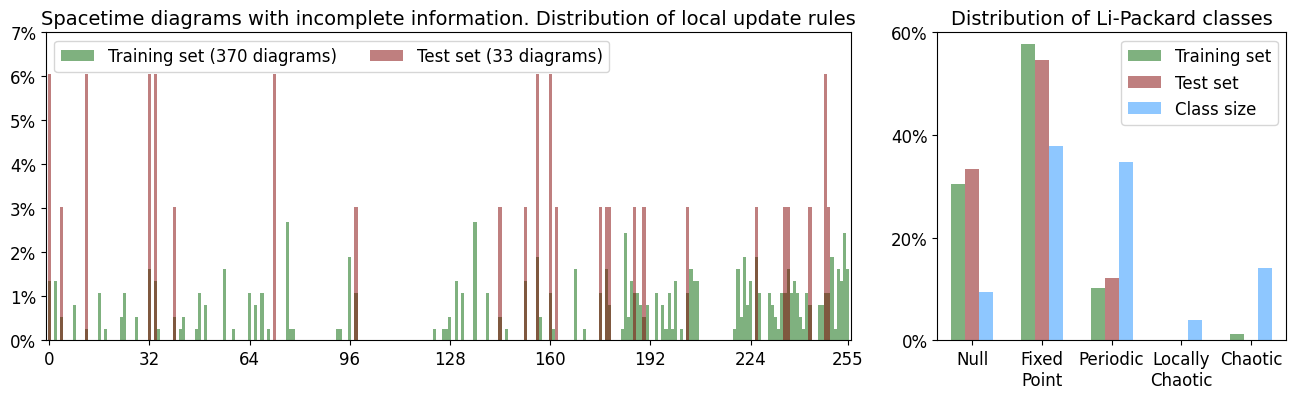

In [10]:
# make histogram of all undetermined rules
SAVEFIG=False
SAVENAME="benchmark_undetermined_diagrams.pdf"

# choose colours
train_color = 'darkgreen'
test_color = 'maroon'
prevalence_color = 'dodgerblue'

# choose font size
ticklabelsize=12
legendsize=12
titlesize=14


# create subplot
figsize=4
title_size=16
fig, axs = plt.subplots(1,2, width_ratios=(3,1.3), figsize=(4*figsize, figsize), squeeze=True)
plt.subplots_adjust(wspace=0.15)

# histogram of undetermined elementary rules
# note: for density to sum to 1, we must use bins of unity width. Here we choose [-0.5, 0.5, ..., 255.5]
bins_rules = np.array(range(257))-0.5
axs[0].hist(undetermined_train_rules, bins=bins_rules, density=True, color=train_color, alpha=.5, label='Training set (370 diagrams)')
axs[0].hist(undetermined_test_rules, bins=bins_rules, density=True, color=test_color, alpha=.5, label='Test set (33 diagrams)')

# set preferred indicators for local update rules
axs[0].set_xlim([-1, 256])
xticks = np.append(np.arange(0, 256, 32), 255)
axs[0].set_xticks(xticks)
axs[0].set_xticklabels(xticks, size=ticklabelsize)

# adjust to percentages
axs[0].set_ylim([0, 0.05])
axs[0].set_yticks(np.linspace(0,0.07,8))
axs[0].set_yticklabels(['0%', '1%', '2%', '3%', '4%', '5%', '6%', '7%'], size=ticklabelsize)

width=0.2
bar_offset=width
undetermined_train_classes_numbers_counts = np.array(undetermined_train_classes_numbers_counts)
undetermined_test_classes_numbers_counts = np.array(undetermined_test_classes_numbers_counts)
axs[1].bar(np.arange(5)-bar_offset, undetermined_train_classes_numbers_counts/sum(undetermined_train_classes_numbers_counts), width=width, color=train_color, alpha=.5, label='Training set')
axs[1].bar(np.arange(5), undetermined_test_classes_numbers_counts/sum(undetermined_test_classes_numbers_counts), width=width, color=test_color, alpha=.5, label='Test set')
axs[1].set_xlim([-.5, 4.5])
axs[1].set_ylim([0, 0.6])
axs[1].set_yticks([0, 0.2, 0.4, 0.6])
axs[1].set_yticklabels(['0%', '20%', '40%', '60%'], size=ticklabelsize)

# add prevalence of every LP class
class_prevalences = []
for key, item in Li_Packard_dict.items():
  class_prevalence = len(item) / 256
  class_prevalences.append(class_prevalence)
axs[1].bar(np.arange(5)+bar_offset, class_prevalences, width=width, color=prevalence_color, alpha=0.5, label='Class size')

LP_classes_labels = ['Null', 'Fixed\nPoint', 'Periodic', 'Locally\nChaotic', 'Chaotic']
axs[1].set_xticks(np.arange(5))
axs[1].set_xticklabels(LP_classes_labels, size=ticklabelsize)

# information
# fig.suptitle('This is a somewhat long figure title', y=1.02, fontsize=titlesize+2, weight='roman')
axs[0].legend(loc='upper left', ncols=2, prop={'size':legendsize})
axs[1].legend(prop={'size':legendsize})
axs[0].set_title("Spacetime diagrams with incomplete information. Distribution of local update rules", fontsize=titlesize)
axs[1].set_title("Distribution of Li-Packard classes", fontsize=titlesize)
# axs[2].set_title("Single wrongly classified diagram\nRule 59 (guessed as 58)", fontsize=titlesize)

if SAVEFIG:
  plt.savefig(f'{images_dir}/{SAVENAME}', bbox_inches='tight')

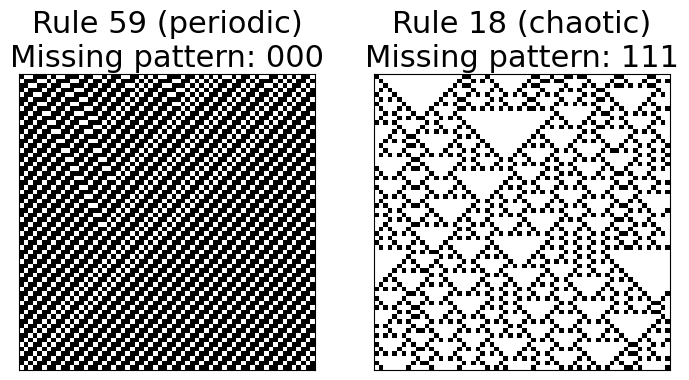

In [17]:
# save?
SAVEFIG=False
SAVENAME="benchmark_undetermined_diagrams_examples2.pdf"

# display some interesting diagrams that make up the statistics above

key_wrongly_classified_diagram = 61264 # index 60
keys_incomplete_chaotic_diagrams = np.array([18547, 130045, 149614, 165294, 187431]) # indices array([ 20,  99, 128, 147, 168]

figsize=4
fontsize=22
fig, axs = plt.subplots(1,2, figsize=(2.1*figsize, figsize), squeeze=True)
# plt.subplots_adjust(wspace=0.05)

first_key_chaotic = keys_incomplete_chaotic_diagrams[0]
second_key_chaotic = keys_incomplete_chaotic_diagrams[3]

axs[0].imshow(x_train_all[key_wrongly_classified_diagram], cmap='Greys')
axs[1].imshow(x_train_all[first_key_chaotic], cmap='Greys')
# axs[2].imshow(x_train_all[second_key_chaotic], cmap='Greys')

axs[0].set_title(f"Rule {undetermined_train[key_wrongly_classified_diagram][0]} (periodic)\nMissing pattern: 000", fontsize=fontsize)
axs[1].set_title(f"Rule {undetermined_train[first_key_chaotic][0]} (chaotic)\nMissing pattern: 111", fontsize=fontsize)
# axs[2].set_title(f"Rule {undetermined_train[second_key_chaotic][0]} (chaotic)\nMissing pattern: 101", fontsize=fontsize)

for i in range(2):
  axs[i].set_xticks([])
  axs[i].set_yticks([])

if SAVEFIG:
  plt.savefig(f'{images_dir}/{SAVENAME}', bbox_inches='tight')

In [ ]:
# not a single diagram has fewer than 7 occuring triplets
for key, item in undetermined_train.items():
  found_triplets = item[1]
  if len(found_triplets) < 7:
    print('found one')

187431
183, {'000'}


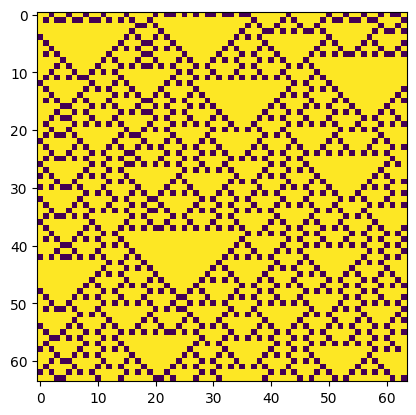

In [ ]:
# x_test_all.shape[0]

# np.where(undetermined_train_classes=='chaotic') # array([ 20,  99, 128, 147, 168]

all_triplets = set({'000', '001', '010', '011', '100', '101', '110', '111'})

for i, (key, item) in enumerate(undetermined_train.items()):
  if i == 168:
    key_chaotic_undetermined = key
    rule = item[0]
    found_triplets = item[1]
    missing_triplets = all_triplets.difference(found_triplets)
    break

print(key_chaotic_undetermined)
print(f'{rule}, {missing_triplets}')
plt.imshow(x_train_all[key_chaotic_undetermined])

In [ ]:
undetermined_train[second_key_chaotic]

(161, {'000', '001', '010', '011', '100', '110', '111'})